## Importação e Limpeza

In [97]:
# !pip install pandas
# !pip install matplotlib.pyplot
# !pip install seaborn
# !pip install openpyxl
# !pip install scikit-learn
# !pip install Plotly
# !pip install --upgrade nbformat


In [139]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import plotly.express as px
from re import search

In [99]:
df:pd.DataFrame = pd.read_excel("../data/raw/ICB_DADOS_2026.xlsx")

In [100]:
df.columns

Index(['Mes_Ano_Data', 'Data_Coleta', 'Estab', 'Produto', 'Marca', 'Preco',
       'Quantidade', 'PPK'],
      dtype='str')

In [101]:
# dividir por produto
df.Produto.unique()

<StringArray>
['Carne Bovina Coxão Mole',                'Manteiga',
                   'Arroz',                    'Café',
             'Pão Francês',                    'Óleo',
                  'Açúcar',        'Farinha de Trigo',
                  'Feijão',            'Banana Prata',
                   'Leite',                  'Tomate',
                  'Batata',           'Banana Nanica',
       'Carne Bovina Acem',            'Frango Peito',
      'Carne Suína Pernil',        'Frango Sobrecoxa',
                     'Ovo',       'Macarrão com Ovos',
    'Carne Bovina Músculo',    'Carne Bovina Patinho',
    'Carne Bovina Alcatra',                 'Farinha',
                'Macarrão',              'Carne Acem',
        'Carne Coxão Mole',                     'Pão',
            'Carne Pernil',                  'Pernil']
Length: 30, dtype: str

### Limpeza

In [102]:
df

,Mes_Ano_Data,Data_Coleta,Estab,Produto,Marca,Preco,Quantidade,PPK
0,2022-09-01,2022-09-23,SUP_33,Carne Bovina Coxão Mole,NaN,54.20,1.0,54.20
1,2022-09-01,2022-09-12,SUP_15,Carne Bovina Coxão Mole,NaN,53.90,1.0,53.90
2,2022-09-01,2022-09-21,SUP_09,Carne Bovina Coxão Mole,NaN,53.90,1.0,53.90
3,2022-09-01,2022-09-23,SUP_12,Carne Bovina Coxão Mole,NaN,51.99,1.0,51.99
4,2022-09-01,2022-09-12,SUP_20,Carne Bovina Coxão Mole,NaN,51.90,1.0,51.90
...,...,...,...,...,...,...,...,...
46259,2026-08-01,NaT,SUP_06,Pernil,NaN,19.99,1.0,19.99
46260,2026-08-01,NaT,SUP_06,Carne Bovina Acem,NaN,39.50,1.0,39.50
46261,2026-08-01,NaT,SUP_06,Carne Bovina Coxão Mole,NaN,56.90,1.0,56.90
46262,2026-08-01,NaT,SUP_06,Frango Peito,NaN,8.99,1.0,8.99


In [103]:
MIN_MESES = 28

meses_por_estab = df.groupby('Estab')['Mes_Ano_Data'].nunique().sort_values(ascending=False)
estabs_validos = meses_por_estab[meses_por_estab >= MIN_MESES].index

linhas_antes = len(df)
df = df[df['Estab'].isin(estabs_validos)].reset_index(drop=True)

print(f'Mercados mantidos: {len(estabs_validos)} de {len(meses_por_estab)}')
print(f'Linhas removidas: {linhas_antes - len(df)} de {linhas_antes} ({(linhas_antes - len(df)) / linhas_antes:.1%})')
print('\nMercados removidos (meses de histórico):')
print(meses_por_estab[meses_por_estab < MIN_MESES])

Mercados mantidos: 28 de 51
Linhas removidas: 2111 de 46264 (4.6%)

Mercados removidos (meses de histórico):
Estab
SUP_29    18
SUP_30    14
SUP_44     3
SUP_45     2
SUP_10     2
SUP_14     2
SUP_23     2
SUP_09     1
ALT_49     1
SUP_03     1
ALT_48     1
SUP_02     1
SUP_05     1
ALT_28     1
ALT_35     1
ALT_26     1
SUP_25     1
SUP_18     1
SUP_21     1
SUP_31     1
SUP_37     1
SUP_40     1
SUP_42     1
Name: Mes_Ano_Data, dtype: int64


In [104]:
df['Marca'][df['Produto']=='Café'].unique()

array(['Pilão', 'Melita', '3 Corações', 'Caboclo', 'Canecão',
       'São Joaquim', 'Moraes', 'Pelé', 'São', 'União', 'Fort', 'Nescafé',
       nan, '3 corações', 'São Joaquim ', 'Outro'], dtype=object)

Precisamos tratar as marcas 3 corações e São Joaquim.

In [105]:
df.loc[df['Marca'].str.contains('3 corações', case=False, na=False), 'Marca'] = '3 Corações'
df.loc[df['Marca'].str.contains('São Joaquim ', case=False, na=False), 'Marca'] = 'São Joaquim'

In [106]:
df

,Mes_Ano_Data,Data_Coleta,Estab,Produto,Marca,Preco,Quantidade,PPK
0,2022-09-01,2022-09-23,SUP_33,Carne Bovina Coxão Mole,NaN,54.20,1.0,54.20
1,2022-09-01,2022-09-12,SUP_15,Carne Bovina Coxão Mole,NaN,53.90,1.0,53.90
2,2022-09-01,2022-09-23,SUP_12,Carne Bovina Coxão Mole,NaN,51.99,1.0,51.99
3,2022-09-01,2022-09-12,SUP_20,Carne Bovina Coxão Mole,NaN,51.90,1.0,51.90
4,2022-09-01,2022-09-26,SUP_13,Carne Bovina Coxão Mole,NaN,50.49,1.0,50.49
...,...,...,...,...,...,...,...,...
44148,2026-08-01,NaT,SUP_06,Pernil,NaN,19.99,1.0,19.99
44149,2026-08-01,NaT,SUP_06,Carne Bovina Acem,NaN,39.50,1.0,39.50
44150,2026-08-01,NaT,SUP_06,Carne Bovina Coxão Mole,NaN,56.90,1.0,56.90
44151,2026-08-01,NaT,SUP_06,Frango Peito,NaN,8.99,1.0,8.99


In [107]:
nomes = {
    "Farinha de Trigo": "Farinha",
    "Carne Acem": "Carne Bovina Acem",
    "Pão Francês": "Pão",
    "Macarrão com Ovos": "Macarrão",
    "Carne Coxão Mole": "Carne Bovina Coxão Mole",
    "Carne Pernil": "Pernil",
    "Carne Suína Pernil": "Pernil",
}
df["Produto"] = df["Produto"].replace(nomes)


In [108]:
df.Produto.unique()

<StringArray>
['Carne Bovina Coxão Mole',                'Manteiga',
                   'Arroz',                    'Café',
                     'Pão',                  'Açúcar',
                 'Farinha',                  'Feijão',
                    'Óleo',            'Banana Prata',
                   'Leite',                  'Tomate',
           'Banana Nanica',                  'Batata',
       'Carne Bovina Acem',            'Frango Peito',
                  'Pernil',        'Frango Sobrecoxa',
                     'Ovo',                'Macarrão',
    'Carne Bovina Músculo',    'Carne Bovina Patinho',
    'Carne Bovina Alcatra']
Length: 23, dtype: str

In [109]:
duplicadas = df[df.duplicated(keep=False)]

print(f"Linhas repetidas: {df.duplicated().sum()}")
duplicadas.sort_values(["Mes_Ano_Data", "Estab", "Produto"])

Linhas repetidas: 1742


,Mes_Ano_Data,Data_Coleta,Estab,Produto,Marca,Preco,Quantidade,PPK
1416,2022-10-01,2022-10-24,SUP_38,Farinha,Dona Benta,6.75,1.0,6.750000
1417,2022-10-01,2022-10-24,SUP_38,Farinha,Dona Benta,6.75,1.0,6.750000
2107,2022-11-01,2022-11-21,SUP_24,Banana Prata,NaN,7.99,1.0,7.990000
2108,2022-11-01,2022-11-21,SUP_24,Banana Prata,NaN,7.99,1.0,7.990000
2114,2022-11-01,2022-11-18,SUP_34,Banana Prata,NaN,7.99,1.0,7.990000
...,...,...,...,...,...,...,...,...
41459,2026-05-01,NaT,SUP_50,Óleo,Soya,7.99,0.9,8.877778
41496,2026-05-01,NaT,SUP_50,Óleo,Liza,7.99,0.9,8.877778
41497,2026-05-01,NaT,SUP_50,Óleo,Soya,7.99,0.9,8.877778
42067,2026-06-01,NaT,SUP_04,Feijão,Outro,8.99,1.0,8.990000


In [110]:
df = df.drop_duplicates()

## Análises

In [111]:
df_cafe = df[df['Produto'] == 'Café']
df_cafe = df_cafe.sort_values('Mes_Ano_Data')

df_pilao = df[df['Marca'] == 'Pilão']
df_3coracoes = df[df['Marca'] == '3 Corações']
df_caboclo = df[df['Marca'] == 'Caboclo']

x = np.array(df_caboclo['Mes_Ano_Data'])
y = np.array(df_caboclo['Preco'])

In [112]:
df_cafe['Marca'].unique()

array(['Pilão', 'Caboclo', '3 Corações', 'Moraes', 'Pelé', 'Canecão',
       'São Joaquim', 'Melita', 'Nescafé', 'São', 'Fort', 'União', nan,
       'Outro'], dtype=object)

In [113]:
df_cafe.groupby('Marca').count().sort_values('Quantidade', ascending=False)


,Mes_Ano_Data,Data_Coleta,Estab,Produto,Preco,Quantidade,PPK
Marca,,,,,,,
3 Corações,1083,896,1083,1083,1083,1083,1083
Melita,895,757,895,895,895,895,895
Pilão,809,685,809,809,809,809,809
Caboclo,775,646,775,775,775,775,775
Canecão,690,556,690,690,690,690,690
São Joaquim,218,173,218,218,218,218,218
Moraes,172,129,172,172,172,172,172
União,155,121,155,155,155,155,155
Fort,53,33,53,53,53,53,53


In [114]:
df_cafe = df_cafe[df_cafe['Marca'] != 'Nescafé']
df_cafe = df_cafe[df_cafe['Marca'] != 'São'] 

In [115]:
df_cafe

,Mes_Ano_Data,Data_Coleta,Estab,Produto,Marca,Preco,Quantidade,PPK
49,2022-09-01,2022-09-21,SUP_39,Café,Pilão,25.99,0.5,51.98
229,2022-09-01,2022-09-12,SUP_43,Café,Caboclo,16.90,0.5,33.80
228,2022-09-01,2022-09-26,SUP_24,Café,Caboclo,16.98,0.5,33.96
227,2022-09-01,2022-09-21,SUP_46,Café,3 Corações,16.98,0.5,33.96
226,2022-09-01,2022-09-26,SUP_41,Café,Pilão,16.99,0.5,33.98
...,...,...,...,...,...,...,...,...
43437,2026-08-01,NaT,SUP_24,Café,Caboclo,29.98,0.5,59.96
43436,2026-08-01,NaT,SUP_24,Café,3 Corações,32.90,0.5,65.80
43435,2026-08-01,NaT,SUP_24,Café,Melita,32.99,0.5,65.98
43398,2026-08-01,NaT,SUP_13,Café,Pelé,30.89,0.5,61.78


In [116]:
def plotar_grafico_por_cada_marca(df, marca:list):
    for m in marca:
        df_marca = df[df['Marca'] == m]
        plt.figure(figsize=(10, 6))
        sns.lineplot(data=df_marca, x='Mes_Ano_Data', y='Preco', marker='o')
        plt.title(f'Preço do Café - {m}')
        plt.xlabel('Mês/Ano')
        plt.ylabel('Preço')
        plt.xticks(rotation=45)
        plt.grid()
        plt.tight_layout()
        plt.show()

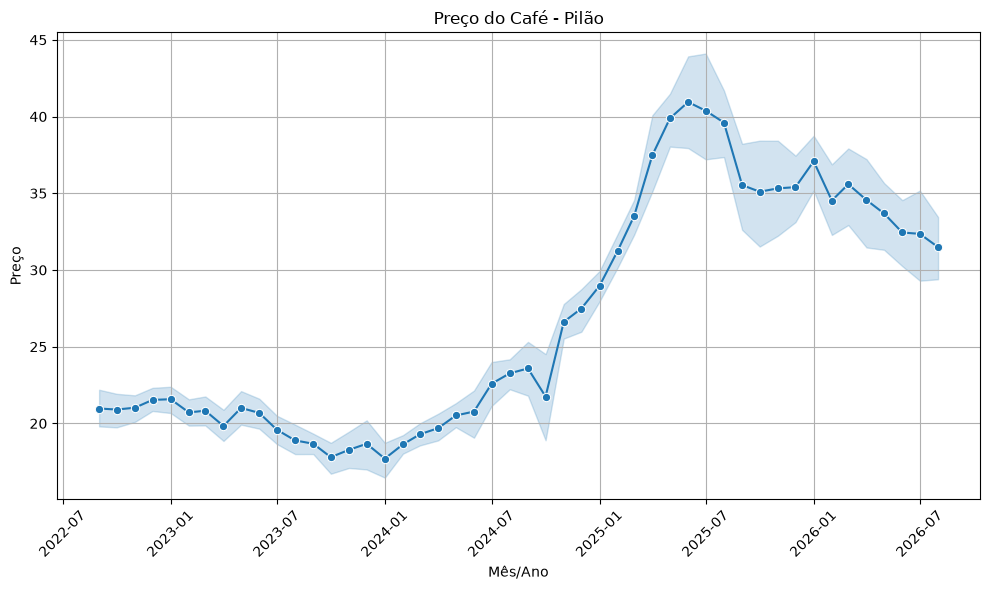

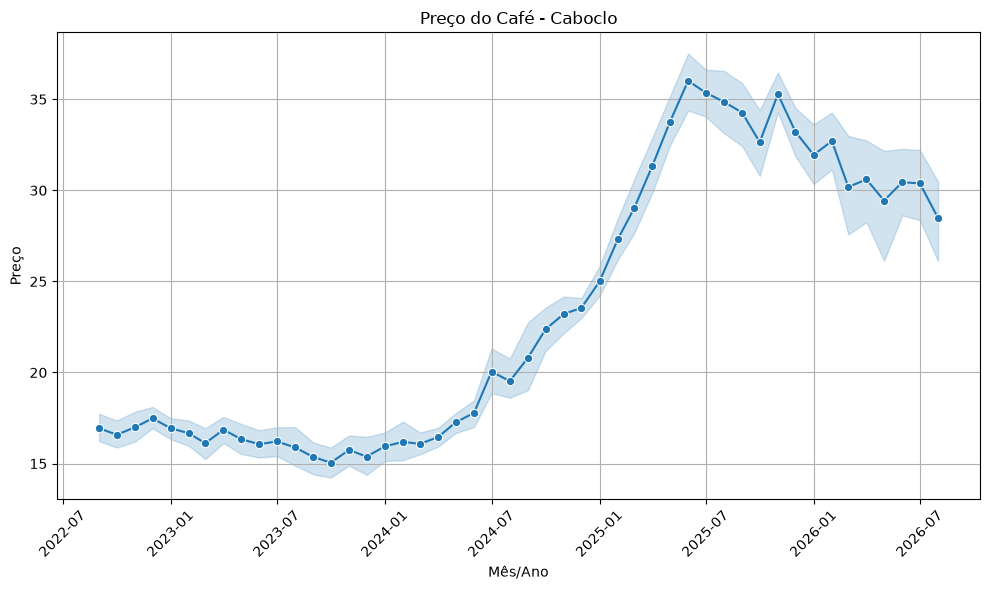

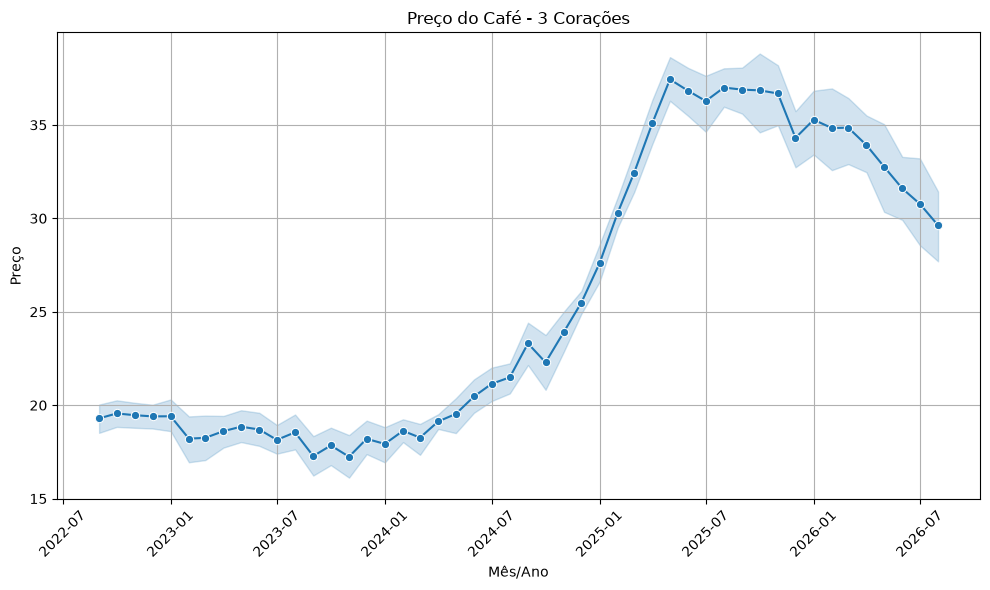

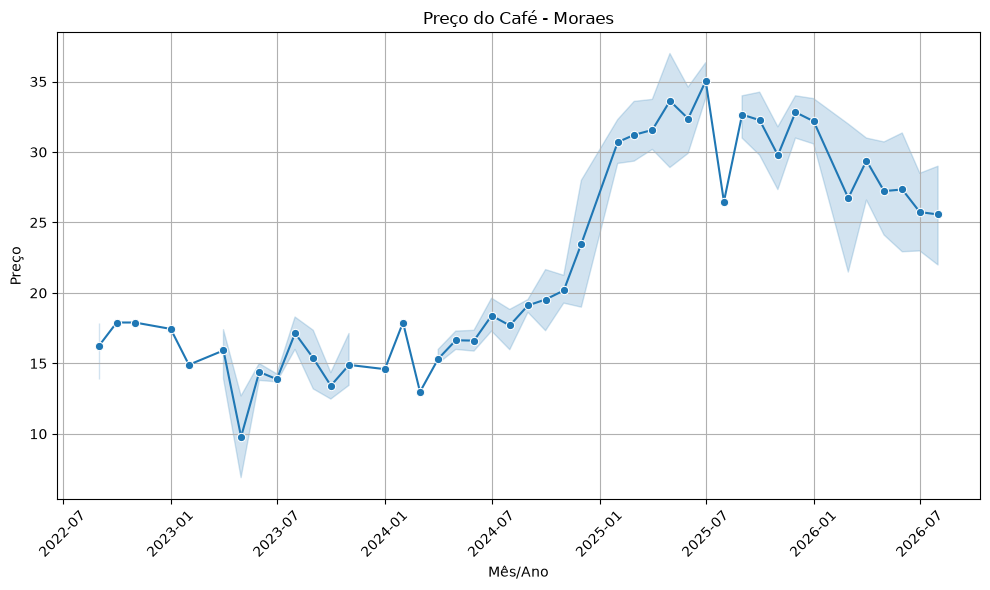

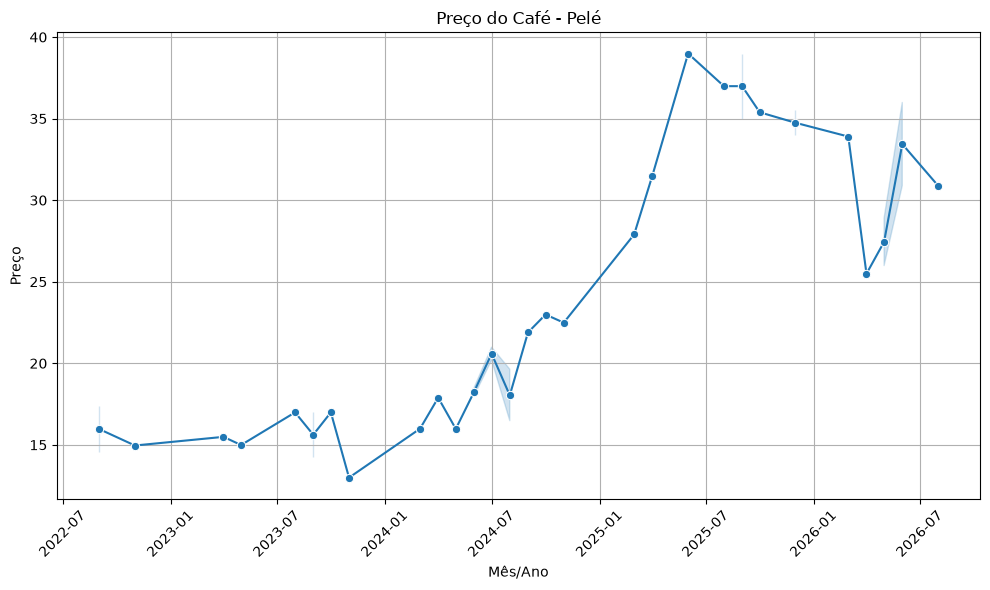

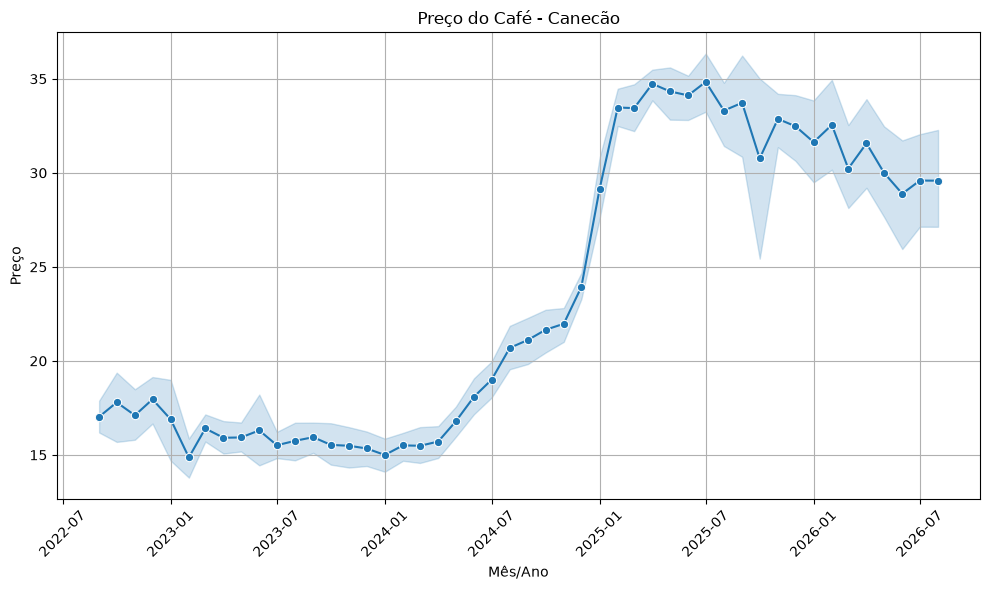

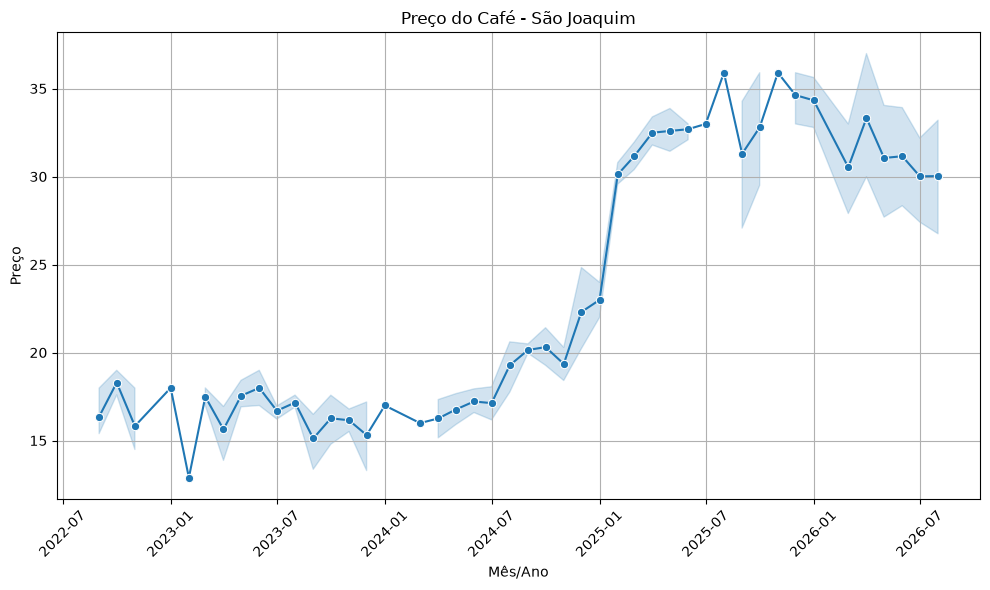

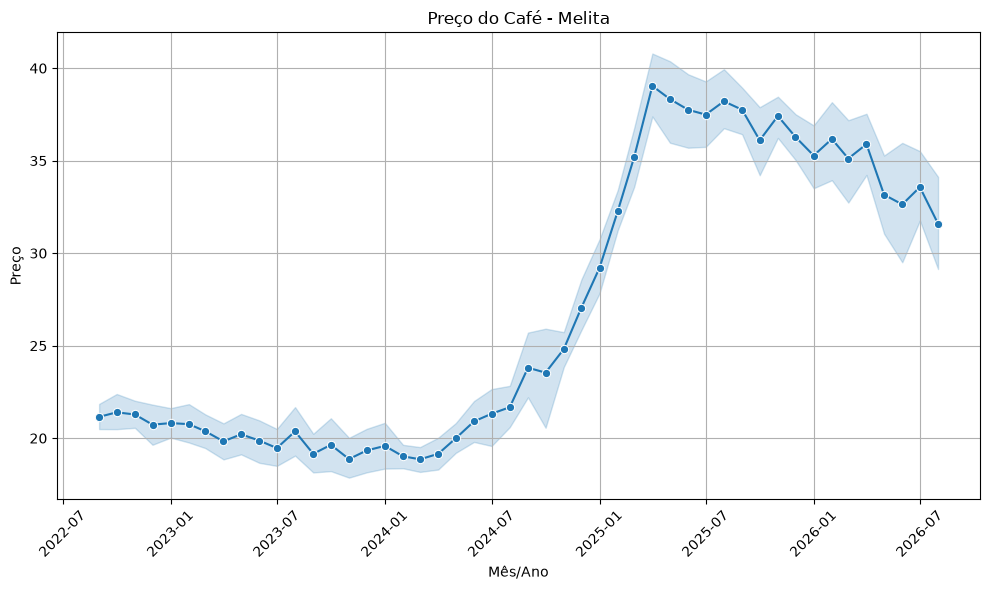

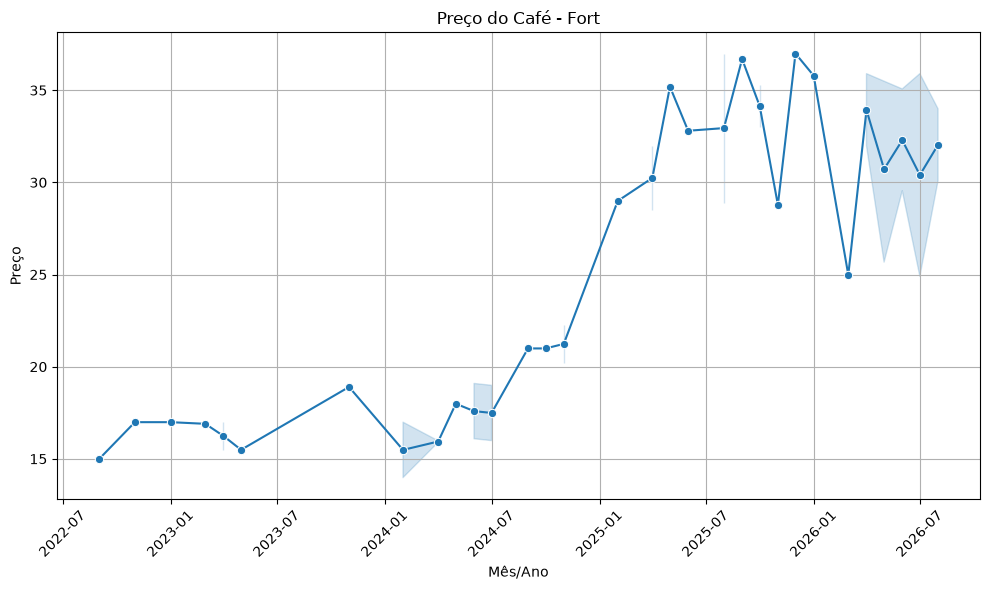

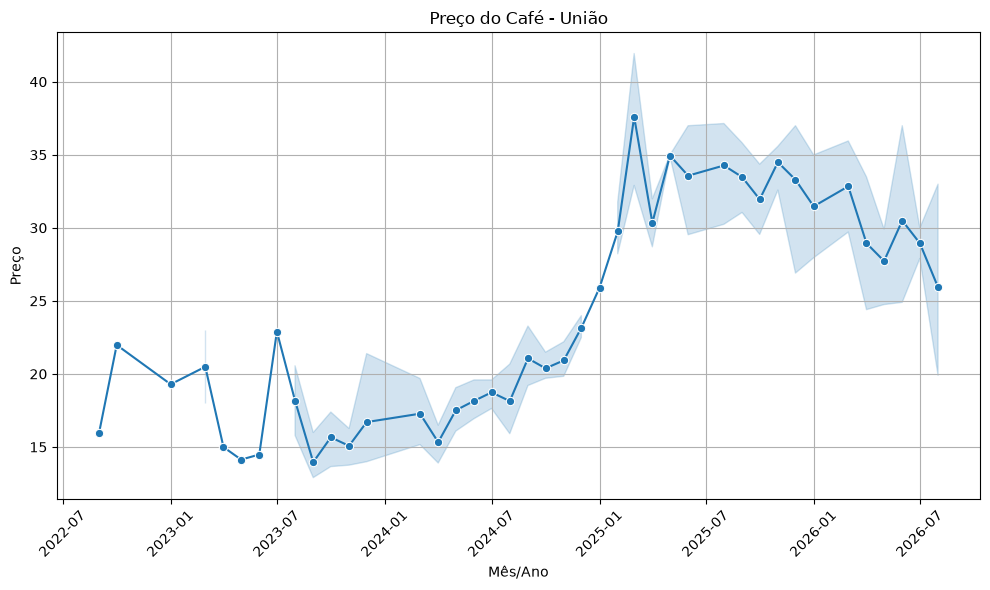

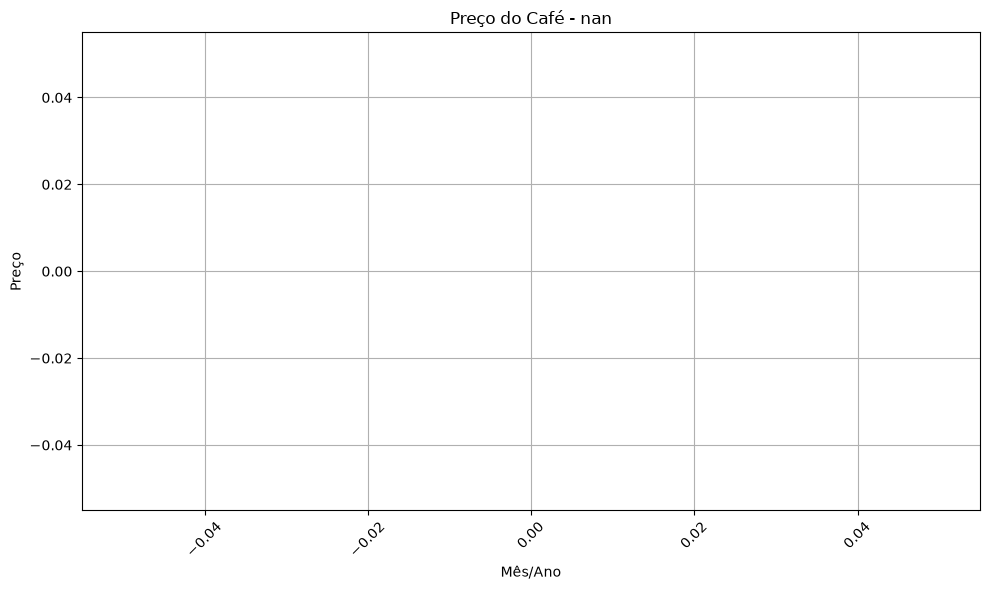

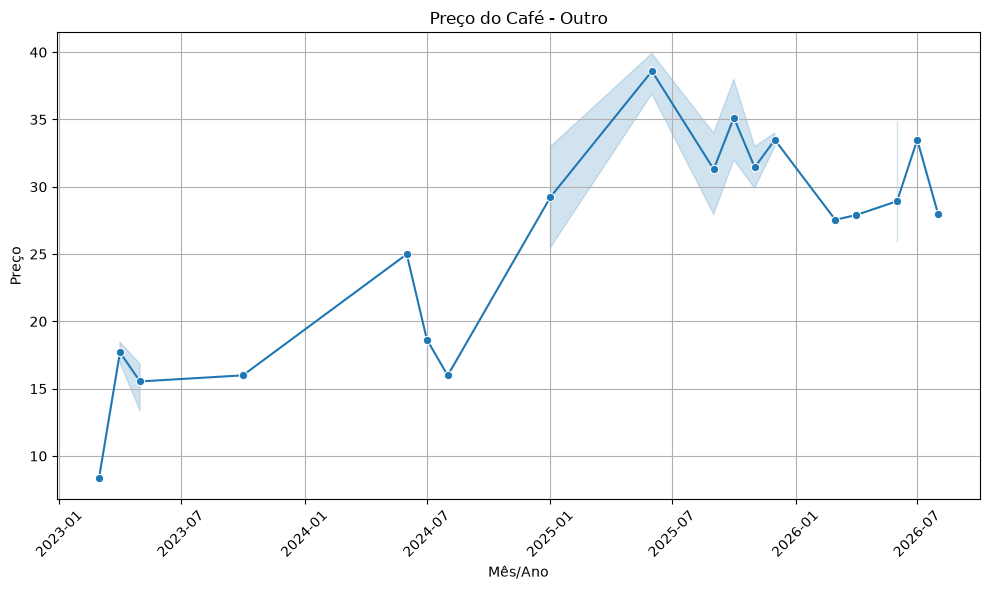

In [117]:
plotar_grafico_por_cada_marca(df_cafe, df_cafe['Marca'].unique())

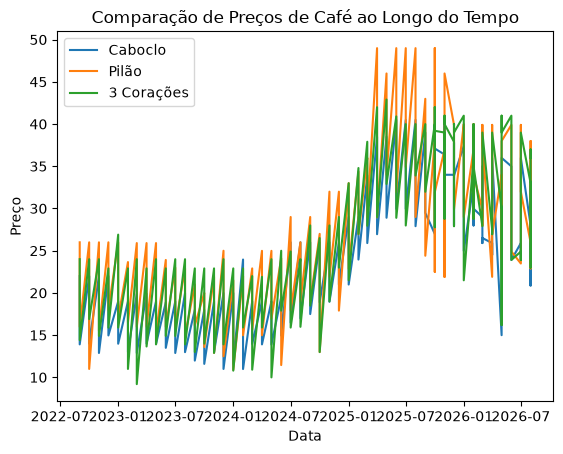

In [118]:
plt.plot(df_caboclo['Mes_Ano_Data'], df_caboclo['Preco'], label='Caboclo')
plt.plot(df_pilao['Mes_Ano_Data'], df_pilao['Preco'], label='Pilão')
plt.plot(df_3coracoes['Mes_Ano_Data'], df_3coracoes['Preco'], label='3 Corações')
plt.title('Comparação de Preços de Café ao Longo do Tempo')
plt.xlabel('Data')
plt.ylabel('Preço')
plt.legend()
plt.show()

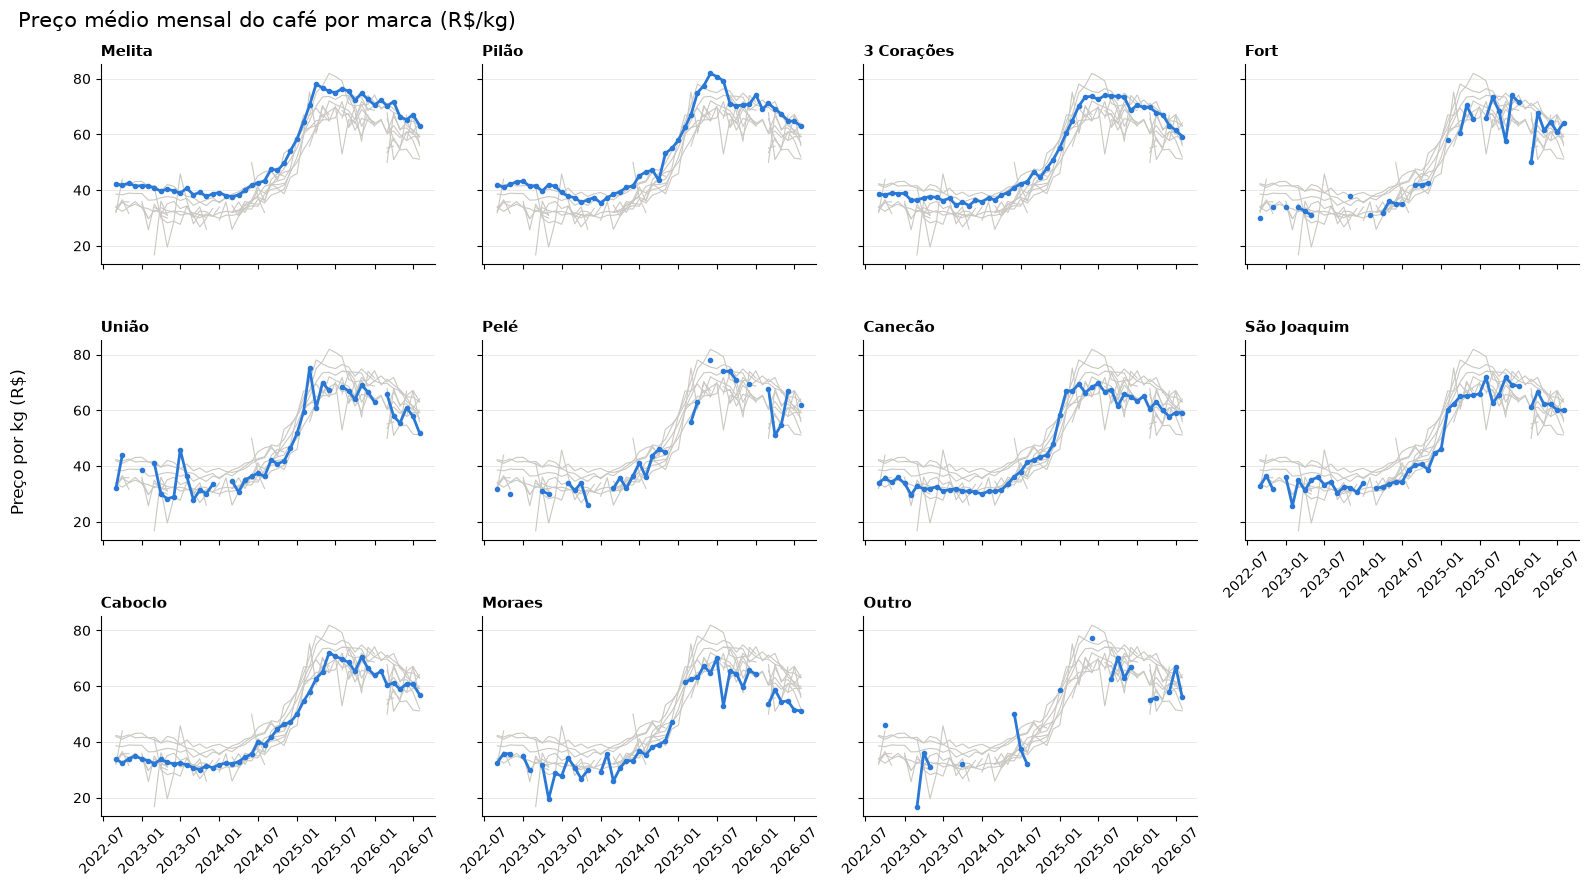

In [119]:
# Padroniza os nomes das marcas (espaços sobrando, maiúsculas/minúsculas, registros incompletos)
marca = df_cafe['Marca'].str.strip().str.title()
marca = marca.replace({'São': 'São Joaquim', 'Nescafé': 'Outro'}).fillna('Outro')

# Média mensal do preço por kg (PPK) de cada marca: uma coluna por marca, uma linha por mês
cafe_mensal = (
    df_cafe.assign(Marca=marca)
    .groupby(['Mes_Ano_Data', 'Marca'])['PPK']
    .mean()
    .unstack('Marca')
)

# Ordena da marca mais cara para a mais barata, deixando "Outro" por último
ordem = cafe_mensal.drop(columns='Outro').mean().sort_values(ascending=False).index.tolist() + ['Outro']

fig, axes = plt.subplots(3, 4, figsize=(16, 9), sharex=True, sharey=True)
for ax, nome in zip(axes.flat, ordem):
    # Todas as marcas em cinza como referência, com a marca do painel em destaque
    ax.plot(cafe_mensal.index, cafe_mensal, color='#c9c8c2', linewidth=0.8)
    ax.plot(cafe_mensal.index, cafe_mensal[nome], color='#2a78d6', linewidth=2, marker='o', markersize=3)
    ax.set_title(nome, loc='left', fontsize=11, fontweight='bold')
    ax.grid(axis='y', color='#e8e7e2', linewidth=0.6)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(axis='x', rotation=45)

# Remove os painéis que sobraram na grade e devolve o eixo de datas ao painel logo acima
for ax in axes.flat[len(ordem):]:
    ax.remove()
axes[1, 3].tick_params(axis='x', labelbottom=True)

fig.suptitle('Preço médio mensal do café por marca (R$/kg)', x=0.01, ha='left', fontsize=15)
fig.supylabel('Preço por kg (R$)', x=0.005)
fig.tight_layout(rect=(0.015, 0, 1, 1))
plt.show()

## Agrupamentos

In [120]:
years = df["Mes_Ano_Data"].dt.year.unique()

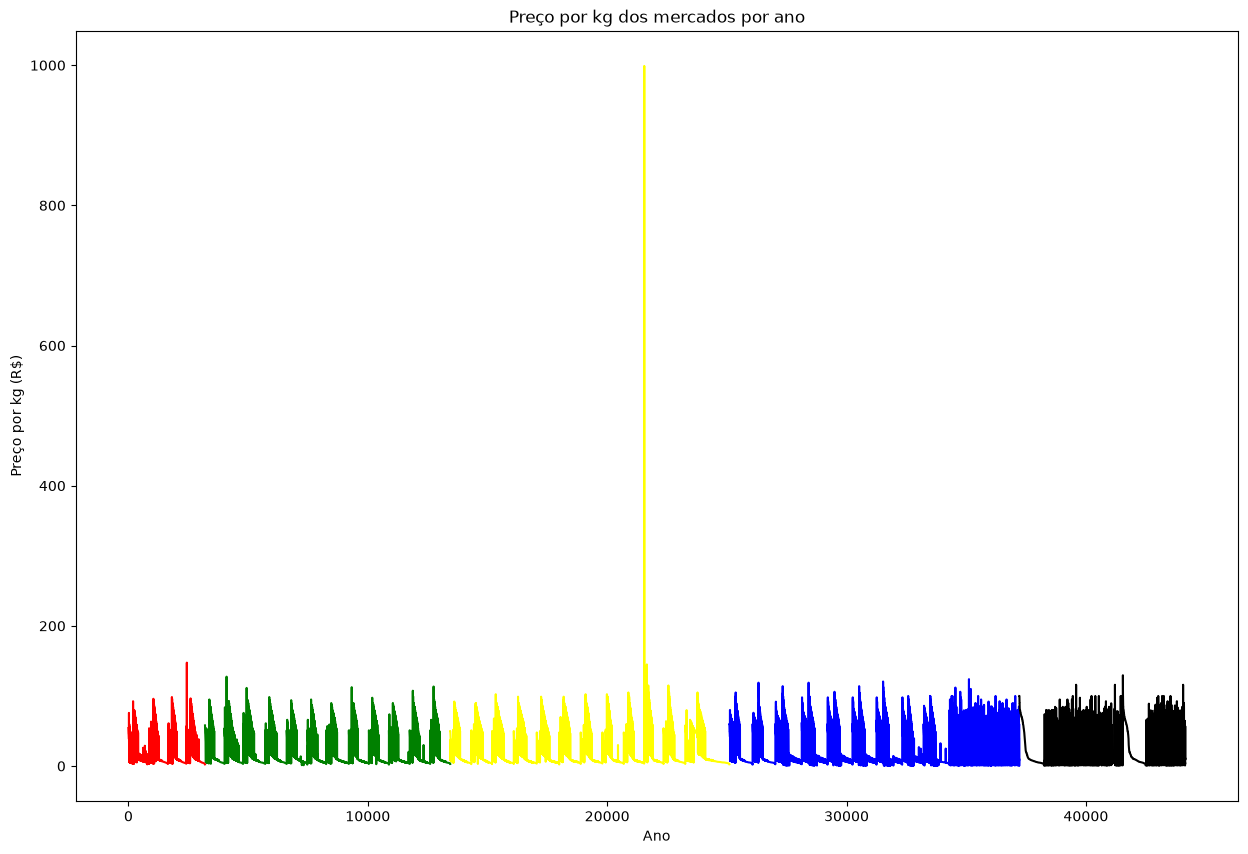

In [121]:
color = ["red","green","yellow","blue","black"]
plt.figure(figsize=(15, 10))
plt.title("Preço por kg dos mercados por ano")
for c, y in enumerate(years):
    plt.plot(df[df["Mes_Ano_Data"].dt.year == y]["PPK"], color = color[c])
plt.xlabel("Ano")
plt.ylabel("Preço por kg (R$)");

Percebemos que existe alguns valores irreais, como preço de carnes saindo à R$0.00 ou uma banana nanica saindo à R$1000.00. Por isso, decidimos criar um dataframe sem esses valores.

In [122]:
df_2 = df.copy()

In [123]:
for produto in df_2["Produto"].unique():
    mediana = df_2[df_2["Produto"] == produto]["PPK"].median()
    irreais = (df_2["Produto"] == produto) & ((df_2["PPK"] > mediana * 3) | (df_2["PPK"] < mediana / 3))
    df_2 = df_2[~irreais]

In [124]:
# quanto o preço está acima/abaixo do "normal" daquele produto naquele mês
# interpretação: 1.0 = na mediana, 0.9 = 10% mais barato, 1.2 = 20% mais caro
mediana_mes = df_2.groupby(["Produto", "Mes_Ano_Data"])["PPK"].transform("median")
df_2["PPK_Relativo"] = df_2["PPK"] / mediana_mes


Criamos uma nova coluna para lidar com possíveis flutuações de preço em um mesmo ano no KMeans. (Exemplo: os preços subirem em Dezembro pode tornar ele um mercado caro na clusterização, mesmo que durante o resto do ano os preços eram estáveis.)

In [125]:
df_2

,Mes_Ano_Data,Data_Coleta,Estab,Produto,Marca,Preco,Quantidade,PPK,PPK_Relativo
0,2022-09-01,2022-09-23,SUP_33,Carne Bovina Coxão Mole,NaN,54.20,1.0,54.20,1.180828
1,2022-09-01,2022-09-12,SUP_15,Carne Bovina Coxão Mole,NaN,53.90,1.0,53.90,1.174292
2,2022-09-01,2022-09-23,SUP_12,Carne Bovina Coxão Mole,NaN,51.99,1.0,51.99,1.132680
3,2022-09-01,2022-09-12,SUP_20,Carne Bovina Coxão Mole,NaN,51.90,1.0,51.90,1.130719
4,2022-09-01,2022-09-26,SUP_13,Carne Bovina Coxão Mole,NaN,50.49,1.0,50.49,1.100000
...,...,...,...,...,...,...,...,...,...
44148,2026-08-01,NaT,SUP_06,Pernil,NaN,19.99,1.0,19.99,1.052659
44149,2026-08-01,NaT,SUP_06,Carne Bovina Acem,NaN,39.50,1.0,39.50,0.920746
44150,2026-08-01,NaT,SUP_06,Carne Bovina Coxão Mole,NaN,56.90,1.0,56.90,1.023565
44151,2026-08-01,NaT,SUP_06,Frango Peito,NaN,8.99,1.0,8.99,0.430144


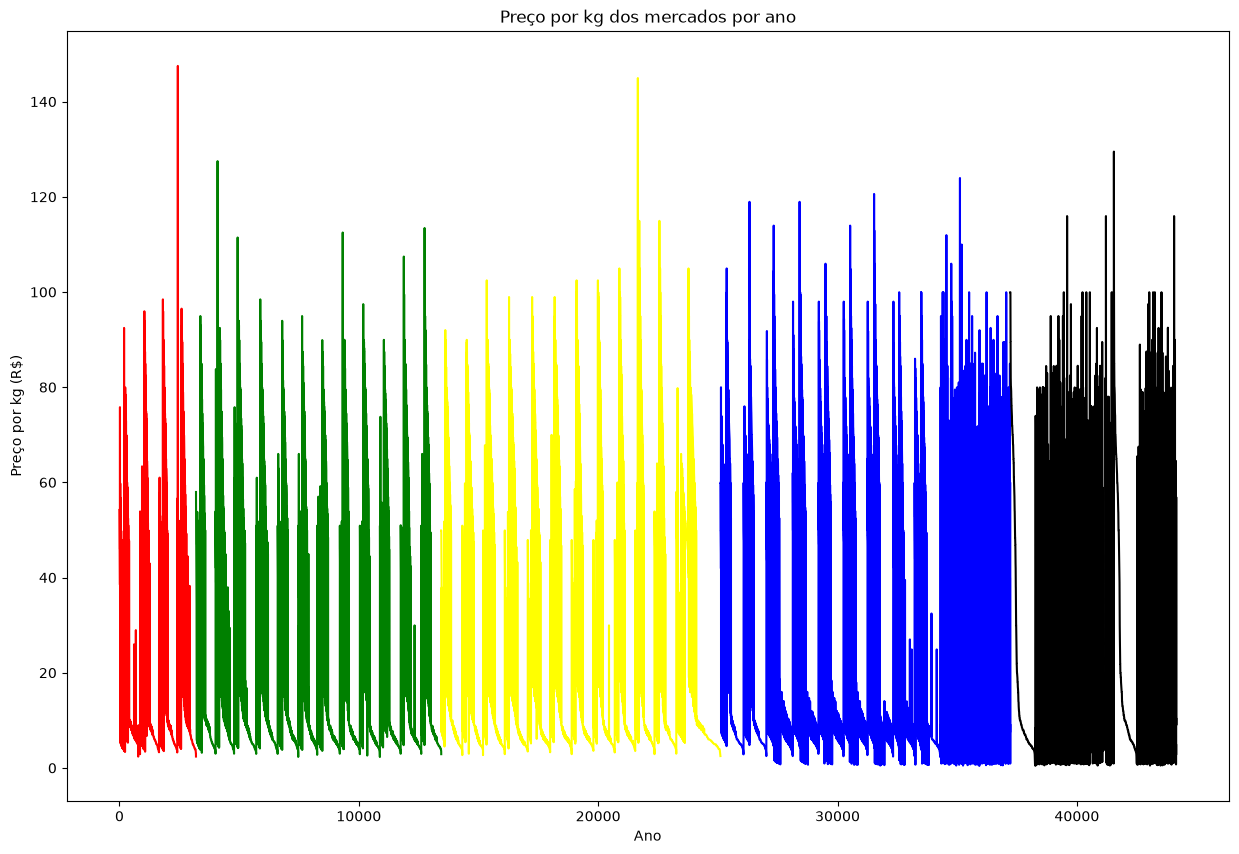

In [126]:
color = ["red","green","yellow","blue","black"]
plt.figure(figsize=(15, 10))
plt.title("Preço por kg dos mercados por ano")
for c, y in enumerate(years):
    plt.plot(df_2[df_2["Mes_Ano_Data"].dt.year == y]["PPK"], color = color[c])
plt.xlabel("Ano")
plt.ylabel("Preço por kg (R$)");

In [127]:
df_2.Produto.unique()

<StringArray>
['Carne Bovina Coxão Mole',                'Manteiga',
                   'Arroz',                    'Café',
                     'Pão',                 'Farinha',
                  'Feijão',                    'Óleo',
            'Banana Prata',                   'Leite',
                  'Açúcar',                  'Tomate',
           'Banana Nanica',                  'Batata',
       'Carne Bovina Acem',            'Frango Peito',
                  'Pernil',        'Frango Sobrecoxa',
                     'Ovo',                'Macarrão',
    'Carne Bovina Músculo',    'Carne Bovina Patinho',
    'Carne Bovina Alcatra']
Length: 23, dtype: str

In [128]:
produto_escolhido = "arroz".title()
df_produto = df_2[df_2["Produto"] == produto_escolhido]

df_2022 = df_produto[df_produto["Mes_Ano_Data"].dt.year == 2022]
df_2023 = df_produto[df_produto["Mes_Ano_Data"].dt.year == 2023]
df_2024 = df_produto[df_produto["Mes_Ano_Data"].dt.year == 2024]
df_2025 = df_produto[df_produto["Mes_Ano_Data"].dt.year == 2025]
df_2026 = df_produto[df_produto["Mes_Ano_Data"].dt.year == 2026]

dfs_ano = [df_2022, df_2023, df_2024, df_2025, df_2026]

for df_ano in dfs_ano:
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(df_ano[["PPK_Relativo"]])

    # 3. Criar e treinar o modelo K-Means (exemplo com K=3)
    kmeans = KMeans(n_clusters=3, random_state=42, n_init='auto')
    kmeans.fit(X_scaled)

    # 4. Obter os rótulos (clusters) de cada linha
    centros = kmeans.cluster_centers_.ravel()
    ordem = sorted(range(3), key=lambda c: centros[c])
    novo_rotulo = {antigo: novo for novo, antigo in enumerate(ordem)}
    df_ano['cluster'] = [novo_rotulo[l] for l in kmeans.labels_]

    # Ver os centroides finais
    print(kmeans.cluster_centers_)

[[ 0.14414088]
 [-1.13290461]
 [ 1.3701328 ]]
[[-0.0308362 ]
 [-1.34251659]
 [ 1.15413646]]
[[ 1.14758704]
 [-1.31190648]
 [ 0.0049619 ]]
[[ 1.05443382]
 [-1.5334763 ]
 [-0.12763359]]
[[-1.38948745]
 [ 1.07993874]
 [-0.05431386]]


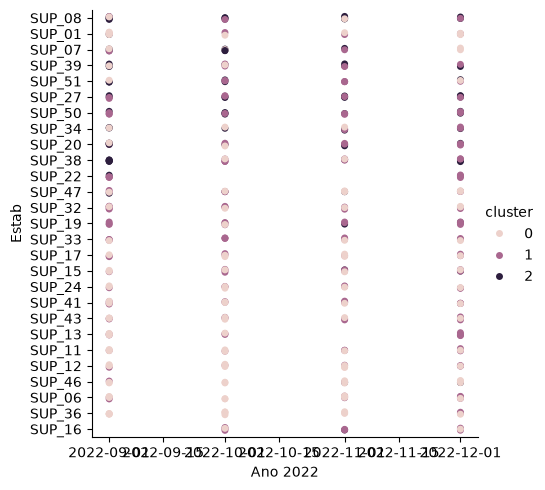

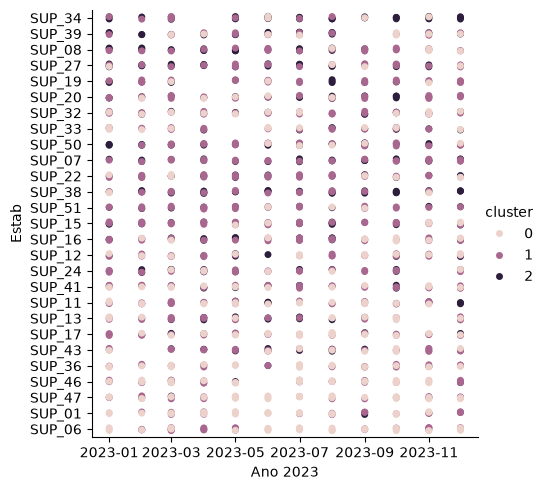

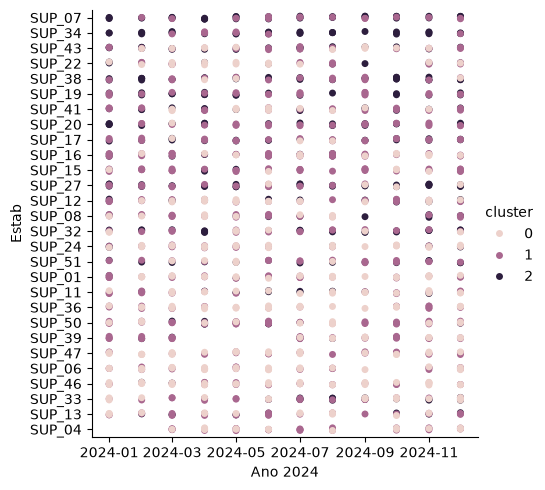

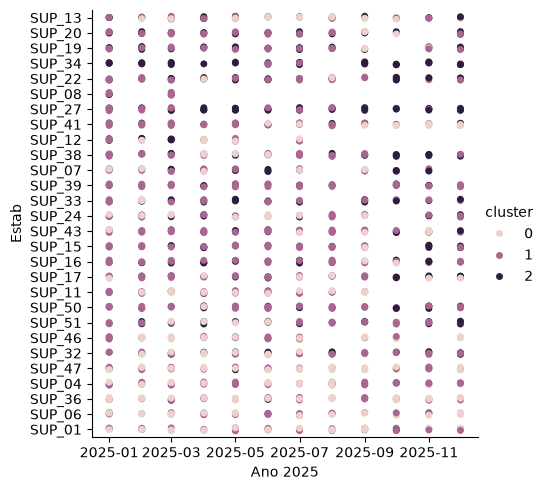

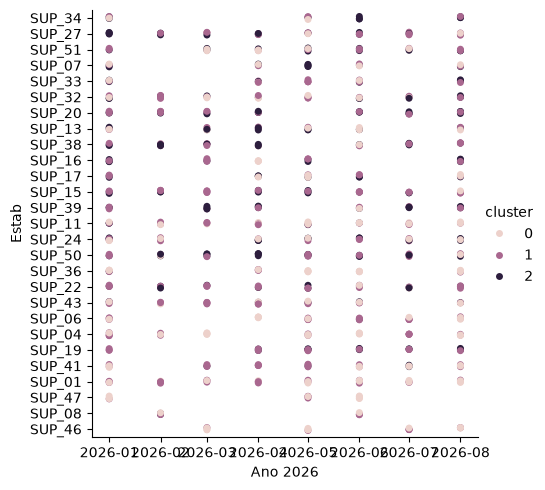

In [129]:
for y, df_ano in enumerate(dfs_ano):
    # sns.scatterplot(data = df_2[df_2["Mes_Ano_Data"].dt.year == y], x = "Mes_Ano_Data", y = "Preco", hue="")
    sns.catplot(data = df_ano, x = "Mes_Ano_Data", y = "Estab", hue="cluster")
    plt.xlabel(f"Ano {years[y]}")
    plt.show()

In [141]:
# alguns estabelecimentos podem vender diferentes marcas
# levando em consideracao que +marcas e -preco = melhor mercado com ofertas
def melhor_mercado(dados: pd.DataFrame, grupo: int) -> list[str]:
    """
    Grupos: 
        0 - mais barato
        1 - preço médio
        2 - mais caros
    """
    estab_mais_aparecem: dict[str, int] = {}
    dados_filtrado = dados[dados["cluster"] == grupo]
    
    if dados_filtrado.empty:
        return []
        
    for estab in dados_filtrado["Estab"]:
        if estab not in estab_mais_aparecem:
            estab_mais_aparecem[estab] = 1
        else:
            estab_mais_aparecem[estab] += 1

    maior_qntd_ofertas = max(estab_mais_aparecem.values())
    melhores_estabs = [
        estab for estab, qntd in estab_mais_aparecem.items() if qntd == maior_qntd_ofertas
    ]
    
    return melhores_estabs


In [142]:
def melhor_mercado_pelo_produto(dados: pd.DataFrame, produto: str, ano: int, grupo: int, coluna:str = "Produto") -> tuple[list[str], str]:
    try:
        produto_escolhido = produto
        dados_produto = dados[dados[coluna] == produto_escolhido]
        dados_ano = dados_produto[dados_produto["Mes_Ano_Data"].dt.year == ano].copy()
        
        #proteção contra poucos dados para o número de clusters do K-Means
        total_amostras = dados_ano.shape[0]
        if total_amostras == 0:
            return (["nenhum"], produto)
            
        n_clusters = 3 if total_amostras >= 3 else total_amostras
        
        scaler = StandardScaler()
        x_scaled = scaler.fit_transform(dados_ano[["PPK_Relativo"]])

        kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init='auto')
        kmeans.fit(x_scaled)

        centros = kmeans.cluster_centers_.ravel()
        ordem = sorted(range(n_clusters), key=lambda c: centros[c])
        novo_rotulo = {antigo: novo for novo, antigo in enumerate(ordem)}
        dados_ano['cluster'] = [novo_rotulo[l] for l in kmeans.labels_]

        return (melhor_mercado(dados_ano, grupo), produto)
        
    except Exception as e:
        return (["nenhum"], produto)


In [143]:
def melhor_mercado_todos_produtos(dados:pd.DataFrame, ano:int, grupo:int, coluna:str = "Produto", mostrar_rank:bool = False)->dict[str,list[str]]|None:
    estab_mais_aparecem:dict[str,list[str]] = {}
    produtos:list[str] = list(dados[coluna].dropna().unique())
    produtos_do_ano:list[str] = list(dados[dados["Mes_Ano_Data"].dt.year == ano][coluna].dropna().unique())
    for p in produtos:
        if(p in produtos_do_ano):
            mercados, produto = melhor_mercado_pelo_produto(dados, p, ano, grupo, coluna)
            for m in mercados:
                if(m not in estab_mais_aparecem):
                    estab_mais_aparecem[m] = [produto]
                else:
                    estab_mais_aparecem[m].append(produto)
    estab_mais_aparecem = dict(
        sorted(estab_mais_aparecem.items(), key=lambda item: len(item[1]), reverse=True)
    )
    if(mostrar_rank):
        print(f"Melhores mercados de {ano}:")
        for i, e in enumerate(estab_mais_aparecem):
            print(f" {i+1}° - {e}:\n\tItens: {', '.join(estab_mais_aparecem[e])}")
    return estab_mais_aparecem

In [144]:
def melhor_mercado_todos_anos(dados: pd.DataFrame, grupo: int, coluna:str = "Produto",mostrar_rank: bool = False) -> dict[str, int]|None:
    """
    Mostra o mercado que mais vezes foi o 'melhor do ano' ao longo de todos os anos.
    """
    estab_mais_aparecem: dict[str, int] = {}
    anos_lista = sorted(dados["Mes_Ano_Data"].dt.year.unique())
    
    for ano in anos_lista:
        mercados_dict = melhor_mercado_todos_produtos(dados, ano, grupo, coluna)

        if not mercados_dict:
            continue
        
        primeiro_mercado = list(mercados_dict.keys())[0]
        if primeiro_mercado not in estab_mais_aparecem:
            estab_mais_aparecem[primeiro_mercado] = 1  # primeira vez que aparece na história dos anos
        else:
            estab_mais_aparecem[primeiro_mercado] += 1 # apareceu em mais um ano
    
    if(mostrar_rank):
        estab_mais_aparecem = dict(
            sorted(estab_mais_aparecem.items(), key=lambda item: item[1], reverse=True)
        )
        print("Mercados:")
        for mercado, vitorias in estab_mais_aparecem.items():
            if grupo == 2:
                print(f"- {mercado}: Foi caro em {vitorias} ano(s)")
            if grupo == 1:
                print(f"- {mercado}: Foi 'mediano' em {vitorias} ano(s)")
            if grupo == 0:
                print(f"- {mercado}: Foi barato em {vitorias} ano(s)")
        return None
    else:
        return estab_mais_aparecem


Se posto "melhor_mercado_todos_produtos(df_2, 2026, 0)", veremos que o Supermercado 04 e o Supermercado 01 empataram com 7 itens de baixo preço cada, mas em produtos diferentes: o Supermercado 04 se destaca em Arroz, Café, Pão, Farinha e Frango Sobrecoxa, e o Supermercado 01 em Feijão, Açúcar, Carne Bovina Acem, Ovo e Macarrão. Os dois têm Manteiga e Óleo baratos.

In [146]:
melhor_mercado_todos_produtos(df_2, 2026, 0, mostrar_rank = True)

Melhores mercados de 2026:
 1° - SUP_04:
	Itens: Manteiga, Arroz, Café, Pão, Farinha, Óleo, Frango Sobrecoxa
 2° - SUP_01:
	Itens: Manteiga, Feijão, Óleo, Açúcar, Carne Bovina Acem, Ovo, Macarrão
 3° - SUP_43:
	Itens: Tomate, Banana Nanica, Batata, Frango Sobrecoxa, Ovo
 4° - SUP_36:
	Itens: Arroz, Frango Peito, Pernil
 5° - SUP_11:
	Itens: Arroz, Banana Prata, Leite
 6° - SUP_24:
	Itens: Carne Bovina Coxão Mole, Frango Peito
 7° - SUP_41:
	Itens: Banana Nanica, Batata


{'SUP_04': ['Manteiga',
  'Arroz',
  'Café',
  'Pão',
  'Farinha',
  'Óleo',
  'Frango Sobrecoxa'],
 'SUP_01': ['Manteiga',
  'Feijão',
  'Óleo',
  'Açúcar',
  'Carne Bovina Acem',
  'Ovo',
  'Macarrão'],
 'SUP_43': ['Tomate', 'Banana Nanica', 'Batata', 'Frango Sobrecoxa', 'Ovo'],
 'SUP_36': ['Arroz', 'Frango Peito', 'Pernil'],
 'SUP_11': ['Arroz', 'Banana Prata', 'Leite'],
 'SUP_24': ['Carne Bovina Coxão Mole', 'Frango Peito'],
 'SUP_41': ['Banana Nanica', 'Batata']}

Uma conclusão sobre qual mercado é o melhor durante os anos pode se tornar imprecisa por depender da quantidade de amostras feitas pelos anos, se o mercado foi visitado no ano, ou se ele existiu desde 2022 (primeiro ano de coleta), o que pode tornar a resposta enviesada por ocorrência.

In [154]:
melhor_mercado_todos_anos(df_2, 2, mostrar_rank = True)

c:\Users\caraf\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\base.py:1403: ConvergenceWarning: Number of distinct clusters (1) found smaller than n_clusters (2). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)


Mercados:
- SUP_33: Foi caro em 2 ano(s)
- SUP_32: Foi caro em 2 ano(s)
- SUP_16: Foi caro em 1 ano(s)


Existem alguns mercados que acabarão sendo os mais baratos por serem os únicos ou um dos poucos que vendem o produto.

In [160]:
melhor_mercado_todos_anos(df_2, 0, mostrar_rank = True)

c:\Users\caraf\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\base.py:1403: ConvergenceWarning: Number of distinct clusters (1) found smaller than n_clusters (2). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)


Mercados:
- SUP_04: Foi barato em 2 ano(s)
- SUP_12: Foi barato em 1 ano(s)
- SUP_06: Foi barato em 1 ano(s)
- SUP_43: Foi barato em 1 ano(s)


- Implementando Filtro (Carne Bovina -> Carne, Frango Coxão -> Frango, Pão Francês -> Pão)

In [157]:
def adicionar_filtro(dados:pd.DataFrame)->pd.DataFrame:
    produtos_unitarios:list[str] = dados["Produto"].unique()
    lista_unitarios:list[str] = []
    for p in produtos_unitarios:
        if(search(r" ", p)):
            lista = p.split()[0]
            if(lista not in lista_unitarios):
                lista_unitarios.append(lista)
        else:
            if(p not in lista_unitarios):
                lista_unitarios.append(p)

    padrao_regex = "^(" + "|".join(lista_unitarios) + ")"
    dados["Produto_Filtro"] = dados["Produto"].str.extract(padrao_regex)
    dados.loc[dados["Produto"] == "Pernil", "Produto_Filtro"] = "Carne"
    return dados

- Exibindo os melhores mercados com um filtro genérico, podemos ver que as classificações mudaram. Antes encontraríamos o Supermercado 33, junto ao 32, como os de preço alto durante 2 anos, mas quando pomos os nomes dos alimentos para algo genérico, vemos que nenhum nesta categoria foi o maior no ranking.

In [164]:
melhor_mercado_todos_anos(df_2, 2, "Produto", True)

c:\Users\caraf\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\base.py:1403: ConvergenceWarning: Number of distinct clusters (1) found smaller than n_clusters (2). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)


Mercados:
- SUP_33: Foi caro em 2 ano(s)
- SUP_32: Foi caro em 2 ano(s)
- SUP_16: Foi caro em 1 ano(s)


In [163]:
# com filtro
# melhor_mercado_todos_produtos(df_2, 2022, 0, "Produto_Filtro")
melhor_mercado_todos_anos(df_2, 2, "Produto_Filtro", True)

Mercados:
- SUP_33: Foi caro em 1 ano(s)
- SUP_16: Foi caro em 1 ano(s)
- SUP_38: Foi caro em 1 ano(s)
- SUP_34: Foi caro em 1 ano(s)
- SUP_32: Foi caro em 1 ano(s)
